# Experiment B — Random Prompt Generation Baseline

**Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis**  
**Member 4 — Experimental Design and Baseline Implementation**

---

## Purpose

This notebook implements **Experiment B**: a **pure random prompt generation baseline**.

To isolate the contribution of evolutionary search (tournament selection, crossover, mutation), we generate **50 unique, valid prompts** using the LLM prompt generator (`experiments/random_baseline.py`) with:
- **No manual seed copying** (`seed_prompts=None`, strictly disjoint from Experiment A's 8 manual prompts)
- **No selection, no crossover, and no mutation**

### Fair Budget Justification
Member 3's GA runs (`05_genetic_algorithm_experiment.ipynb`, `06_multi_seed_experiment.ipynb`) ran `POPULATION_SIZE = 12` for `GENERATIONS = 10` (`120` population slots; `49` uncached prompt evaluations / `48,951` texts in seed `42`, and `49–59` uncached prompt evaluations / mean `54,612` texts across seeds `[42, 7, 123]`).  
Evaluating **`N_RANDOM_CANDIDATES = 50`** on `1,000` `opt` examples (`50,000` classifications) gives Experiment B a directly comparable optimization budget.

### Controlled Protocol (identical across A, B, and C)
- **Dataset**: SST-2 (`data/processed/` — 53,871 `opt` / 13,468 `val`)
- **Model**: `Qwen/Qwen2.5-1.5B-Instruct` (revision `989aa798`, greedy decoding for classification)
- **Optimization sample**: 1,000 stratified examples (`seed=42`)
- **Validation split**: all **13,468** examples in `data/processed/val.csv`, evaluated **once** after selecting the best candidate
- **Test set**: never loaded or touched

## 1. Environment Setup

In [1]:
import os
import sys
import json
import subprocess
import random
import time
import importlib.util
from pathlib import Path

REPO_URL = "https://github.com/sarrazer24/evolutionary-prompt-optimization.git"
REPO_DIR = Path("/kaggle/working/evolutionary-prompt-optimization")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--branch", "main", "--single-branch", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    if not (REPO_DIR / ".git").exists():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git repository.")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", "main"], check=True)
    status = subprocess.run(
        ["git", "-C", str(REPO_DIR), "status", "--porcelain"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    if not status:
        subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "main"], check=True)
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", "main"], check=True)
    else:
        print("⚠ Working tree has local changes; skipping git pull.")

os.chdir(REPO_DIR)

REQUIRED_PACKAGES = {
    "transformers": "transformers",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "sklearn": "scikit-learn",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
}
missing_packages = [
    pkg for mod, pkg in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(mod) is None
]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages],
        check=True,
    )
else:
    print("All required packages are already installed.")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    capture_output=True, text=True, check=True,
).stdout.strip()
print("Project directory:", Path.cwd())
print("Git HEAD:", commit)
print("Python version:", sys.version)
print("Setup complete.")

⚠ Working tree has local changes; skipping git pull.
All required packages are already installed.
Project directory: /kaggle/working/evolutionary-prompt-optimization
Git HEAD: f1d0556
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Setup complete.


From https://github.com/sarrazer24/evolutionary-prompt-optimization
 * branch            main       -> FETCH_HEAD


## 2. Imports and Reproducibility

In [2]:
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datetime import datetime
from IPython.display import display, FileLink

from src.data.sst2_data import load_saved_splits, stratified_sample
from src.llm.config import ModelConfig
from src.llm.model_interface import LLMInterface
from src.prompts.baseline_prompts import get_baseline_prompt_texts
from src.prompts.validation import normalize_prompt
from src.evaluation.evaluation import PredictionCache, evaluate_prompt, save_results
from experiments.random_baseline import generate_random_prompts

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Global seed: {SEED}")

Global seed: 42


## 3. GPU Check

In [3]:
if not torch.cuda.is_available():
    print("⚠  No GPU detected — inference will be very slow on CPU.")
    print("   On Kaggle: Settings → Accelerator → GPU T4 x2.")
else:
    for i in range(torch.cuda.device_count()):
        name = torch.cuda.get_device_name(i)
        mem  = torch.cuda.get_device_properties(i).total_memory / 1e9
        print(f"GPU {i}: {name}  ({mem:.1f} GB)")

GPU 0: Tesla T4  (15.6 GB)
GPU 1: Tesla T4  (15.6 GB)


## 4. Experiment Configuration

In [4]:
DATA_DIR            = Path("data/processed")
N_RANDOM_CANDIDATES = 50      # Matches GA seed-42 uncached evals (49) across 10 gens (48,951 texts)
N_OPT_EXAMPLES      = 1_000   # Stratified sample from data/processed/opt.csv (seed 42)
OUTPUT_DIR          = Path("experiments/results/experiment_B_random")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENT_CONFIG = {
    "experiment": "B",
    "name": "random_prompt_generation_baseline",
    "description": "50 purely LLM-generated unique prompts — no manual seeds, no evolutionary pressure",
    "dataset": "nyu-mll/glue:sst2",
    "data_dir": str(DATA_DIR),
    "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
    "inference": {"greedy": True, "max_new_tokens": 8, "batch_size": 32},
    "generation": {
        "method": "llm_assisted_pure_random",
        "n_candidates": N_RANDOM_CANDIDATES,
        "manual_seeds_included": False,
        "no_selection": True,
        "no_crossover": True,
        "no_mutation": True,
    },
    "budget_justification": "GA ran 10 generations (pop=12): seed 42 used 49 uncached prompt evaluations (48,951 texts); 50 random candidates = 50,000 opt text evaluations.",
    "split_seed": 42,
    "evaluation_seed": SEED,
    "n_opt_examples": N_OPT_EXAMPLES,
    "val_sampling": "full_validation_split",
    "metric_primary": "f1_macro",
    "metric_secondary": ["accuracy", "precision_macro", "recall_macro", "invalid_rate"],
    "test_set_used": False,
    "created_at": datetime.now().isoformat(),
}

print(json.dumps(EXPERIMENT_CONFIG, indent=2))

{
  "experiment": "B",
  "name": "random_prompt_generation_baseline",
  "description": "50 purely LLM-generated unique prompts \u2014 no manual seeds, no evolutionary pressure",
  "dataset": "nyu-mll/glue:sst2",
  "data_dir": "data/processed",
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "inference": {
    "greedy": true,
    "max_new_tokens": 8,
    "batch_size": 32
  },
  "generation": {
    "method": "llm_assisted_pure_random",
    "n_candidates": 50,
    "manual_seeds_included": false,
    "no_selection": true,
    "no_crossover": true,
    "no_mutation": true
  },
  "budget_justification": "GA ran 10 generations (pop=12): seed 42 used 49 uncached prompt evaluations (48,951 texts); 50 random candidates = 50,000 opt text evaluations.",
  "split_seed": 42,
  "evaluation_seed": 42,
  "n_opt_examples": 1000,
  "val_sampling": "full_validation_split",
  "metric_primary": "f1_macro",
  "metric_secondary": [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "invalid_rate"
  

## 5. Load Canonical Data (`data/processed/`)

In [5]:
for fname in ("opt.csv", "val.csv", "split_info.json"):
    if not (DATA_DIR / fname).exists():
        raise FileNotFoundError(f"Missing canonical split file: {DATA_DIR / fname}")

splits = load_saved_splits(str(DATA_DIR))
opt_df = splits.opt
val_df = splits.val

assert len(opt_df) == 53871, f"Expected 53871 opt rows in data/processed, got {len(opt_df)}"
assert len(val_df) == 13468, f"Expected 13468 val rows in data/processed, got {len(val_df)}"

print(f"Canonical splits loaded from: {DATA_DIR}")
print(f"Optimisation split : {len(opt_df):>6,} rows  (positive: {opt_df['label'].mean():.1%})")
print(f"Validation split   : {len(val_df):>6,} rows  (positive: {val_df['label'].mean():.1%})")

opt_sample = stratified_sample(opt_df, n=N_OPT_EXAMPLES, seed=SEED)
opt_texts  = opt_sample["text"].tolist()
opt_labels = opt_sample["label"].tolist()

val_texts  = val_df["text"].astype(str).tolist()
val_labels = val_df["label"].astype(int).tolist()
N_VAL_EXAMPLES = len(val_texts)
EXPERIMENT_CONFIG["n_val_examples"] = N_VAL_EXAMPLES

(OUTPUT_DIR / "experiment_config.json").write_text(
    json.dumps(EXPERIMENT_CONFIG, indent=4, ensure_ascii=False), encoding="utf-8"
)

print(f"\nOpt sample : {len(opt_texts)} examples  (counts: {opt_sample['label'].value_counts().sort_index().to_dict()})")
print(f"Val split  : {N_VAL_EXAMPLES:,} examples  (positive: {sum(val_labels)/len(val_labels):.1%})")

Canonical splits loaded from: data/processed
Optimisation split : 53,871 rows  (positive: 55.8%)
Validation split   : 13,468 rows  (positive: 55.8%)

Opt sample : 1000 examples  (counts: {0: 442, 1: 558})
Val split  : 13,468 examples  (positive: 55.8%)


## 6. Load the LLM

In [6]:
model_config = ModelConfig()
llm = LLMInterface(model_config)
llm.load_model()
print(f"Model loaded: {llm.model_id}")
print(f"Device      : {llm.device}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Model loaded: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Device      : cuda:0


## 7. Pure Random Prompt Generation (`seed_prompts=None`)

Uses `experiments.random_baseline.generate_random_prompts` with Member 2's 8 manual prompts explicitly excluded so Experiment B is strictly independent of Experiment A.

In [7]:
manual_prompts = get_baseline_prompt_texts()

print(f"Generating {N_RANDOM_CANDIDATES} pure random candidates (seed={SEED}, manual prompts excluded)...")
t0 = time.perf_counter()
unique_candidates, gen_stats = generate_random_prompts(
    llm=llm,
    n=N_RANDOM_CANDIDATES,
    seed=SEED,
    excluded_prompts=manual_prompts,
)
elapsed_gen = time.perf_counter() - t0

assert len(unique_candidates) == N_RANDOM_CANDIDATES
assert gen_stats["manual_overlap_count"] == 0

print(f"Generated {len(unique_candidates)} unique random prompts in {elapsed_gen:.1f}s")
print("Generation stats:", gen_stats)
print()
for i, p in enumerate(unique_candidates[:5], 1):
    print(f"[{i}] {p}")
if len(unique_candidates) > 5:
    print(f"  … {len(unique_candidates) - 5} more …")

Generating 50 pure random candidates (seed=42, manual prompts excluded)...
Generated 50 unique random prompts in 63.7s
Generation stats: {'n_requested': 50, 'n_generated': 50, 'seed': 42, 'manual_seeds_included': False, 'manual_overlap_count': 0, 'stage1_count': 30, 'stage2_extra_calls': 39, 'stage2_rejections': {'must mention both labels: positive and negative': 6, 'near_duplicate': 11, 'contains a placeholder; the review is supplied separately': 2}}

[1] Given a movie review text, classify it as positive or negative. Answer with exactly one word: positive or negative.
[2] Please label each movie review as positive or negative, ignoring negation, sarcasm, and irony. Answer with exactly one word: positive or negative.
[3] Please classify the sentiment of the following movie review as positive or negative. Answer with one word: positive or negative.
[4] Decide if the text is positive or negative. Answer with exactly one word: positive or negative.
[5] Please classify the following text 

## 8. Evaluate Every Random Candidate on the Optimisation Sample

In [8]:
cache_B = PredictionCache()
raw_opt_results = []
opt_results = []

t_eval_start = time.perf_counter()
for idx, prompt in enumerate(unique_candidates, 1):
    candidate_id = f"random_{idx:03d}"
    print(f"[{idx}/{len(unique_candidates)}] {candidate_id}")
    t0 = time.perf_counter()
    result = evaluate_prompt(
        prompt=prompt,
        examples=opt_texts,
        labels=opt_labels,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache_B,
        split_name="opt",
    )
    elapsed = time.perf_counter() - t0
    raw_opt_results.append(result)
    m = result["metrics"]
    opt_results.append({
        "rank": None,
        "candidate_id": candidate_id,
        "prompt_text": prompt,
        "macro_f1": round(m["f1_macro"], 6),
        "accuracy": round(m["accuracy"], 6),
        "precision_macro": round(m["precision_macro"], 6),
        "recall_macro": round(m["recall_macro"], 6),
        "n_invalid": m["n_invalid"],
        "invalid_rate": round(m["invalid_rate"], 6),
        "n_examples": m["n_examples"],
        "n_cached": result["n_cached"],
        "n_model_texts": result["n_model_texts"],
        "split": "opt",
        "elapsed_s": round(elapsed, 2),
    })
    print(f"   Macro F1 = {m['f1_macro']:.4f}  |  Accuracy = {m['accuracy']:.4f}  |  Invalid = {m['n_invalid']}  |  {elapsed:.1f}s")

elapsed_opt_eval = time.perf_counter() - t_eval_start
opt_results.sort(key=lambda r: r["macro_f1"], reverse=True)
for rank, r in enumerate(opt_results, 1):
    r["rank"] = rank

print(f"\nAll {len(opt_results)} random candidates evaluated in {elapsed_opt_eval:.1f}s.")

[1/50] random_001
   Macro F1 = 0.9227  |  Accuracy = 0.9230  |  Invalid = 0  |  10.6s
[2/50] random_002
   Macro F1 = 0.9118  |  Accuracy = 0.9120  |  Invalid = 0  |  11.5s
[3/50] random_003
   Macro F1 = 0.9316  |  Accuracy = 0.9320  |  Invalid = 0  |  10.3s
[4/50] random_004
   Macro F1 = 0.9406  |  Accuracy = 0.9410  |  Invalid = 0  |  10.0s
[5/50] random_005
   Macro F1 = 0.9326  |  Accuracy = 0.9330  |  Invalid = 0  |  10.1s
[6/50] random_006
   Macro F1 = 0.9282  |  Accuracy = 0.9280  |  Invalid = 1  |  10.2s
[7/50] random_007
   Macro F1 = 0.9227  |  Accuracy = 0.9230  |  Invalid = 0  |  10.5s
[8/50] random_008
   Macro F1 = 0.8763  |  Accuracy = 0.8750  |  Invalid = 3  |  21.7s
[9/50] random_009
   Macro F1 = 0.9138  |  Accuracy = 0.9140  |  Invalid = 0  |  14.1s
[10/50] random_010
   Macro F1 = 0.9217  |  Accuracy = 0.9220  |  Invalid = 0  |  11.9s
[11/50] random_011
   Macro F1 = 0.9424  |  Accuracy = 0.9430  |  Invalid = 0  |  9.7s
[12/50] random_012
   Macro F1 = 0.9385  |

## 9. Optimisation-Split Leaderboard

In [9]:
df_opt = pd.DataFrame(opt_results)[
    ["rank", "candidate_id", "macro_f1", "accuracy", "precision_macro", "recall_macro", "n_invalid", "invalid_rate", "elapsed_s"]
]
display(df_opt.set_index("rank"))

best_candidate = opt_results[0]["candidate_id"]
best_prompt    = opt_results[0]["prompt_text"]
best_f1_opt    = opt_results[0]["macro_f1"]

print(f"\n✔ Best random candidate: '{best_candidate}'  (Macro F1 = {best_f1_opt:.4f})")
print(f"  Text: {best_prompt}")

f1_values = [r["macro_f1"] for r in opt_results]
print(f"\nF1 distribution (all {len(f1_values)} pure random candidates):")
print(f"  Mean   : {np.mean(f1_values):.4f}")
print(f"  Median : {np.median(f1_values):.4f}")
print(f"  Std    : {np.std(f1_values):.4f}")
print(f"  Min    : {np.min(f1_values):.4f}")
print(f"  Max    : {np.max(f1_values):.4f}")

,candidate_id,macro_f1,accuracy,precision_macro,recall_macro,n_invalid,invalid_rate,elapsed_s
rank,,,,,,,,
1,random_047,0.943479,0.944,0.942146,0.945588,0,0.000,11.82
2,random_032,0.943388,0.944,0.942409,0.944647,0,0.000,9.63
3,random_033,0.942481,0.943,0.941124,0.944692,0,0.000,12.18
4,random_011,0.942413,0.943,0.941276,0.943986,0,0.000,9.68
5,random_004,0.940591,0.941,0.939198,0.944075,0,0.000,10.01
6,random_027,0.939532,0.940,0.938097,0.942474,0,0.000,10.10
7,random_012,0.938513,0.939,0.937084,0.941343,0,0.000,10.67
8,random_034,0.936681,0.937,0.935787,0.941432,0,0.000,11.00
9,random_013,0.935628,0.936,0.934475,0.939830,0,0.000,10.11



✔ Best random candidate: 'random_047'  (Macro F1 = 0.9435)
  Text: Label the sentiment of the text as positive or negative, using only evaluative language, ignoring plot descriptions. Answer with exactly one word: positive or negative.

F1 distribution (all 50 pure random candidates):
  Mean   : 0.9191
  Median : 0.9227
  Std    : 0.0194
  Min    : 0.8644
  Max    : 0.9435


## 10. Visualise Random Baseline Results

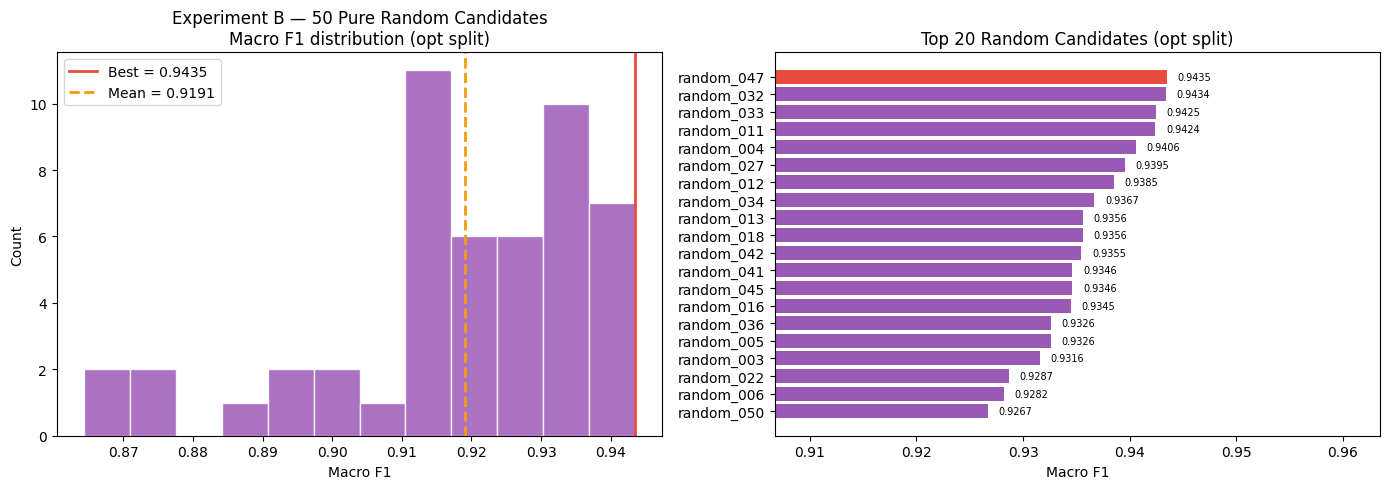

Figure saved → experiments/results/experiment_B_random/random_candidates_opt.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

f1_sorted = [r["macro_f1"] for r in opt_results]

axes[0].hist(f1_sorted, bins=12, color="#9b59b6", edgecolor="white", alpha=0.85)
axes[0].axvline(best_f1_opt, color="#e74c3c", linewidth=2, label=f"Best = {best_f1_opt:.4f}")
axes[0].axvline(np.mean(f1_sorted), color="#f39c12", linewidth=2, linestyle="--", label=f"Mean = {np.mean(f1_sorted):.4f}")
axes[0].set_xlabel("Macro F1")
axes[0].set_ylabel("Count")
axes[0].set_title(f"Experiment B — {len(opt_results)} Pure Random Candidates\nMacro F1 distribution (opt split)")
axes[0].legend()

top_n = min(20, len(opt_results))
top   = opt_results[:top_n]
names = [r["candidate_id"] for r in top][::-1]
f1s   = [r["macro_f1"]    for r in top][::-1]
cols  = ["#e74c3c"] + ["#9b59b6"] * (top_n - 1)
axes[1].barh(names, f1s, color=cols[::-1])
axes[1].set_xlabel("Macro F1")
axes[1].set_title(f"Top {top_n} Random Candidates (opt split)")
axes[1].set_xlim(max(0, min(f1s) - 0.02), min(1, max(f1s) + 0.02))
for v, y in zip(f1s, range(top_n)):
    axes[1].text(v + 0.001, y, f"{v:.4f}", va="center", fontsize=7)

plt.tight_layout()
plot_path = OUTPUT_DIR / "random_candidates_opt.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved → {plot_path}")

## 11. Validate the Best Random Candidate (Full 13,468-row Validation Split)

In [11]:
print(f"Validating best random candidate: '{best_candidate}' on {N_VAL_EXAMPLES:,} examples...")
print(f"Prompt text: {best_prompt}\n")

t0 = time.perf_counter()
val_result = evaluate_prompt(
    prompt=best_prompt,
    examples=val_texts,
    labels=val_labels,
    predict_fn=llm.predict_raw_batch,
    model_id=llm.model_id,
    inference_config=llm.inference_config,
    split_name="val",
)
elapsed_val = time.perf_counter() - t0

vm = val_result["metrics"]
val_summary = {
    "candidate_id":    best_candidate,
    "prompt_text":     best_prompt,
    "macro_f1":        round(vm["f1_macro"],       6),
    "accuracy":        round(vm["accuracy"],        6),
    "precision_macro": round(vm["precision_macro"], 6),
    "recall_macro":    round(vm["recall_macro"],    6),
    "n_invalid":       vm["n_invalid"],
    "invalid_rate":    round(vm["invalid_rate"],    6),
    "n_examples":      vm["n_examples"],
    "confusion_matrix": vm["confusion_matrix"],
    "split":           "val",
    "elapsed_s":       round(elapsed_val, 2),
}

print(f"Validation Macro F1 : {vm['f1_macro']:.4f}")
print(f"Validation Accuracy : {vm['accuracy']:.4f}")
print(f"Invalid count/rate  : {vm['n_invalid']} ({vm['invalid_rate']:.4%})")
print(f"Elapsed             : {elapsed_val:.1f}s")

Validating best random candidate: 'random_047' on 13,468 examples...
Prompt text: Label the sentiment of the text as positive or negative, using only evaluative language, ignoring plot descriptions. Answer with exactly one word: positive or negative.

Validation Macro F1 : 0.9314
Validation Accuracy : 0.9321
Invalid count/rate  : 1 (0.0074%)
Elapsed             : 159.9s


## 12. Save Comparison-Ready Results

In [12]:
# ── Standard Member 1 evaluation format ───────────────────────────────────────
save_results(raw_opt_results, OUTPUT_DIR / "experiment_B_opt_std.csv", append=False)
save_results(raw_opt_results, OUTPUT_DIR / "experiment_B_opt_std.json", include_predictions=False)

# ── Ranked CSV + JSON leaderboard ─────────────────────────────────────────────
opt_csv_path  = OUTPUT_DIR / "experiment_B_opt_results.csv"
opt_json_path = OUTPUT_DIR / "experiment_B_opt_results.json"
pd.DataFrame(opt_results).to_csv(opt_csv_path, index=False)
opt_json_path.write_text(json.dumps(opt_results, indent=2, ensure_ascii=False), encoding="utf-8")

# ── Validation result (includes y_pred for exact McNemar reuse in Notebook 09) ─
val_csv_path  = OUTPUT_DIR / "experiment_B_val_best.csv"
val_json_path = OUTPUT_DIR / "experiment_B_val_best.json"
save_results(val_result, val_csv_path, append=False)
val_payload = dict(val_summary)
val_payload["model_id"] = llm.model_id
val_payload["inference_config"] = llm.inference_config
val_payload["y_pred"] = val_result["y_pred"]
val_json_path.write_text(json.dumps(val_payload, indent=2, ensure_ascii=False), encoding="utf-8")

# ── Comparison-ready summary (consumed by Notebook 09) ───────────────────────
comparison_payload = {
    "experiment": "B",
    "method": "random_generation",
    "data_dir": str(DATA_DIR),
    "n_candidates": len(unique_candidates),
    "manual_seeds_included": False,
    "manual_overlap_count": gen_stats["manual_overlap_count"],
    "n_opt_examples": N_OPT_EXAMPLES,
    "n_val_examples": N_VAL_EXAMPLES,
    "best_candidate_id": best_candidate,
    "best_prompt_text": best_prompt,
    "best_macro_f1_opt": best_f1_opt,
    "best_accuracy_opt": opt_results[0]["accuracy"],
    "best_macro_f1_val": val_summary["macro_f1"],
    "best_accuracy_val": val_summary["accuracy"],
    "best_precision_val": val_summary["precision_macro"],
    "best_recall_val": val_summary["recall_macro"],
    "best_n_invalid_val": val_summary["n_invalid"],
    "generation_elapsed_s": round(elapsed_gen, 2),
    "opt_eval_elapsed_s": round(elapsed_opt_eval, 2),
    "val_elapsed_s": val_summary["elapsed_s"],
    "generation_stats": gen_stats,
    "llm_stats": dict(llm.stats),
    "f1_distribution": {
        "mean":   round(float(np.mean(f1_values)),   6),
        "median": round(float(np.median(f1_values)), 6),
        "std":    round(float(np.std(f1_values)),    6),
        "min":    round(float(np.min(f1_values)),    6),
        "max":    round(float(np.max(f1_values)),    6),
    },
    "all_opt_results": opt_results,
    "model_id": llm.model_id,
    "model_revision": model_config.revision,
    "seed": SEED,
    "created_at": datetime.now().isoformat(),
}

summary_path = OUTPUT_DIR / "experiment_B_summary.json"
summary_path.write_text(json.dumps(comparison_payload, indent=4, ensure_ascii=False, default=str), encoding="utf-8")

ZIP_PATH = "/kaggle/working/experiment_B_random"
shutil.make_archive(ZIP_PATH, "zip", root_dir=str(OUTPUT_DIR))
print("Saved all Experiment B outputs to:", OUTPUT_DIR)
display(FileLink(ZIP_PATH + ".zip"))

Saved all Experiment B outputs to: experiments/results/experiment_B_random


/kaggle/working/experiment_B_random.zip

## 13. Final Summary

In [13]:
print("=" * 60)
print("EXPERIMENT B — PURE RANDOM PROMPT BASELINE")
print("=" * 60)
print(f"Data source             : {DATA_DIR}")
print(f"Pure random candidates  : {len(unique_candidates)} (manual overlap: {gen_stats['manual_overlap_count']})")
print(f"Opt examples per prompt : {N_OPT_EXAMPLES:,}")
print(f"Val examples (best)     : {N_VAL_EXAMPLES:,}")
print(f"Generation time         : {elapsed_gen:.1f}s")
print(f"Opt evaluation time     : {elapsed_opt_eval:.1f}s")
print(f"LLM classified texts    : {llm.stats['classified_texts']:,}")
print()
print(f"Best candidate          : {best_candidate}")
print(f"  Opt  Macro F1         : {best_f1_opt:.4f}")
print(f"  Val  Macro F1         : {val_summary['macro_f1']:.4f}")
print(f"  Val  Accuracy         : {val_summary['accuracy']:.4f}")
print()
print(f"F1 distribution (all {len(f1_values)} candidates):")
print(f"  Mean = {np.mean(f1_values):.4f}  |  Std = {np.std(f1_values):.4f}  |  Min = {np.min(f1_values):.4f}  |  Max = {np.max(f1_values):.4f}")
print()
print("Output files:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name}")
print()
print("Next step: run Notebook 09 (Experiment C — Full Three-Way Comparison)")

EXPERIMENT B — PURE RANDOM PROMPT BASELINE
Data source             : data/processed
Pure random candidates  : 50 (manual overlap: 0)
Opt examples per prompt : 1,000
Val examples (best)     : 13,468
Generation time         : 63.7s
Opt evaluation time     : 580.3s
LLM classified texts    : 63,345

Best candidate          : random_047
  Opt  Macro F1         : 0.9435
  Val  Macro F1         : 0.9314
  Val  Accuracy         : 0.9321

F1 distribution (all 50 candidates):
  Mean = 0.9191  |  Std = 0.0194  |  Min = 0.8644  |  Max = 0.9435

Output files:
  experiment_B_opt_results.csv
  experiment_B_opt_results.json
  experiment_B_opt_std.csv
  experiment_B_opt_std.json
  experiment_B_summary.json
  experiment_B_val_best.csv
  experiment_B_val_best.json
  experiment_config.json
  random_candidates_opt.png

Next step: run Notebook 09 (Experiment C — Full Three-Way Comparison)
